Dataset shape: (178, 13)

First 5 rows:
   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0    14.23        1.71  2.43               15.6      127.0           2.80   
1    13.20        1.78  2.14               11.2      100.0           2.65   
2    13.16        2.36  2.67               18.6      101.0           2.80   
3    14.37        1.95  2.50               16.8      113.0           3.85   
4    13.24        2.59  2.87               21.0      118.0           2.80   

   flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   od280/od315_of_dilu

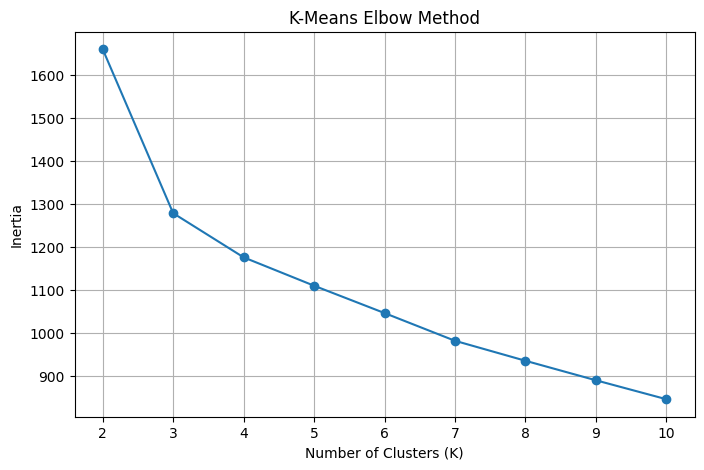

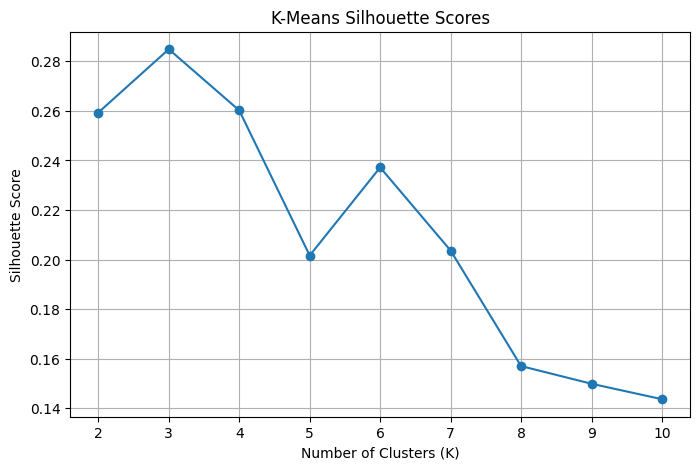


MiniBatchKMeans
----------------------------
Number of clusters: 3
Training time: 0.016921 seconds
Inertia: 1292.329412453579


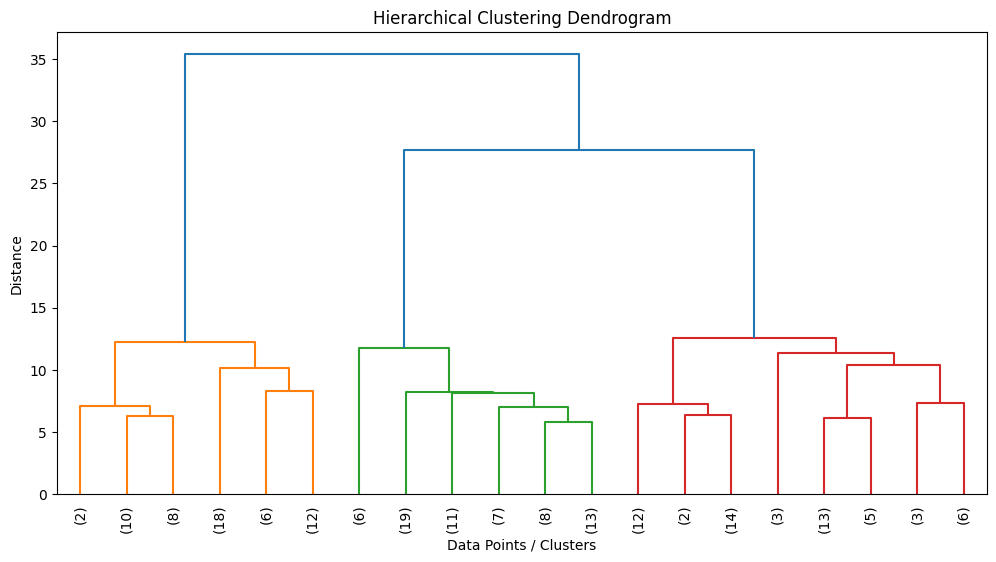

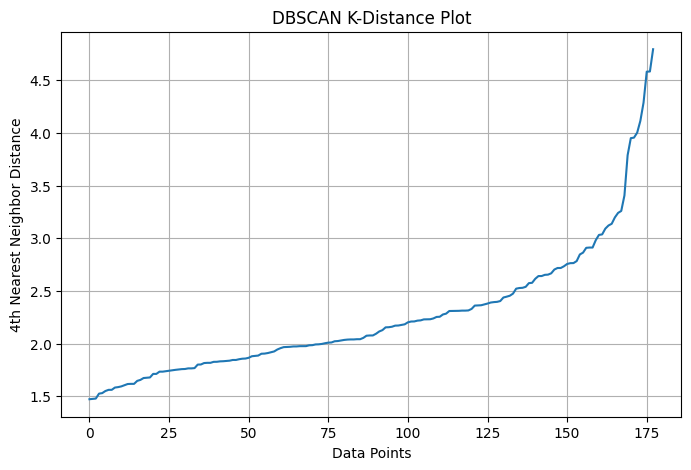


Selected DBSCAN epsilon: 3.4640943187526307

DBSCAN Cluster Labels:
[ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0 -1  0  0  0  0  0  0  0  0  0 -1  0  0
  0 -1  0  0  0  0 -1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0 -1
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0 -1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0]

Number of clusters: 1
Number of noise points: 6


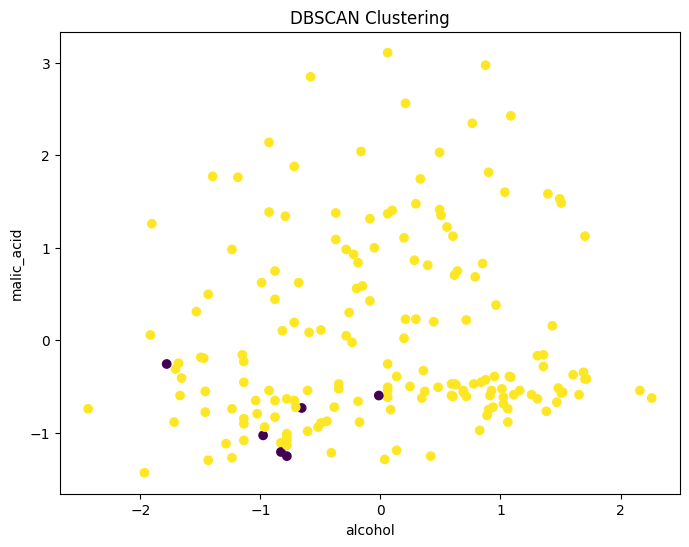


Cluster Profile Table:
           alcohol  malic_acid       ash  alcalinity_of_ash   magnesium  \
Cluster                                                                   
0        12.250923    1.897385  2.231231          20.063077   92.738462   
1        13.134118    3.307255  2.417647          21.241176   98.666667   
2        13.676774    1.997903  2.466290          17.462903  107.967742   

         total_phenols  flavanoids  nonflavanoid_phenols  proanthocyanins  \
Cluster                                                                     
0             2.247692    2.050000              0.357692         1.624154   
1             1.683922    0.818824              0.451961         1.145882   
2             2.847581    3.003226              0.292097         1.922097   

         color_intensity       hue  od280/od315_of_diluted_wines      proline  
Cluster                                                                        
0               2.973077  1.062708                    

In [1]:
# 1. IMPORT LIBRARIES
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import (
    KMeans,
    MiniBatchKMeans,
    DBSCAN
)
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors

from scipy.cluster.hierarchy import dendrogram, linkage


# ============================================================
# 2. LOAD DATASET
# ============================================================

data = load_wine()

X = pd.DataFrame(
    data.data,
    columns=data.feature_names
)

print("Dataset shape:", X.shape)
print("\nFirst 5 rows:")
print(X.head())


# ============================================================
# 3. SCALE DATA
# ============================================================

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled = pd.DataFrame(
    X_scaled,
    columns=X.columns
)

print("\nScaled data:")
print(X_scaled.head())


# ============================================================
# 4. K-MEANS ELBOW METHOD + SILHOUETTE SCORE
# ============================================================

k_range = range(2, 11)

inertia_values = []
silhouette_values = []

for k in k_range:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    # Inertia
    inertia_values.append(
        kmeans.inertia_
    )

    # Silhouette score
    silhouette_values.append(
        silhouette_score(
            X_scaled,
            labels
        )
    )


# ============================================================
# 5. ELBOW PLOT
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    list(k_range),
    inertia_values,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("K-Means Elbow Method")

plt.xticks(list(k_range))

plt.grid(True)

plt.show()


# ============================================================
# 6. SILHOUETTE SCORE PLOT
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    list(k_range),
    silhouette_values,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("K-Means Silhouette Scores")

plt.xticks(list(k_range))

plt.grid(True)

plt.show()


# ============================================================
# 7. MINIBATCH K-MEANS TIMING
# ============================================================

mini_k = 3

start_time = pd.Timestamp.now()

mini_kmeans = MiniBatchKMeans(
    n_clusters=mini_k,
    random_state=42,
    batch_size=32,
    n_init=10
)

mini_labels = mini_kmeans.fit_predict(
    X_scaled
)

end_time = pd.Timestamp.now()

mini_time = (
    end_time - start_time
).total_seconds()

print("\nMiniBatchKMeans")
print("----------------------------")
print("Number of clusters:", mini_k)
print("Training time:", mini_time, "seconds")
print("Inertia:", mini_kmeans.inertia_)


# ============================================================
# 8. HIERARCHICAL CLUSTERING - DENDROGRAM
# ============================================================

# Calculate linkage
linked = linkage(
    X_scaled,
    method="ward"
)

plt.figure(figsize=(12, 6))

dendrogram(
    linked,
    truncate_mode="lastp",
    p=20,
    leaf_rotation=90,
    leaf_font_size=10
)

plt.title(
    "Hierarchical Clustering Dendrogram"
)

plt.xlabel("Data Points / Clusters")
plt.ylabel("Distance")

plt.show()


# ============================================================
# 9. DBSCAN K-DISTANCE PLOT
# ============================================================

# Number of nearest neighbors
k = 4

neighbors = NearestNeighbors(
    n_neighbors=k
)

neighbors.fit(X_scaled)

distances, indices = neighbors.kneighbors(
    X_scaled
)

# Take distance to kth nearest neighbor
k_distances = distances[:, k - 1]

# Sort distances
k_distances = np.sort(
    k_distances
)

plt.figure(figsize=(8, 5))

plt.plot(
    k_distances
)

plt.xlabel("Data Points")
plt.ylabel("4th Nearest Neighbor Distance")

plt.title(
    "DBSCAN K-Distance Plot"
)

plt.grid(True)

plt.show()


# ============================================================
# 10. SELECT EPSILON
# ============================================================

# Use 95th percentile as an example
# for selecting epsilon

eps_value = np.percentile(
    k_distances,
    95
)

print("\nSelected DBSCAN epsilon:", eps_value)


# ============================================================
# 11. DBSCAN CLUSTERING
# ============================================================

dbscan = DBSCAN(
    eps=eps_value,
    min_samples=4
)

dbscan_labels = dbscan.fit_predict(
    X_scaled
)

print("\nDBSCAN Cluster Labels:")
print(dbscan_labels)

print(
    "\nNumber of clusters:",
    len(set(dbscan_labels)) -
    (1 if -1 in dbscan_labels else 0)
)

print(
    "Number of noise points:",
    list(dbscan_labels).count(-1)
)


# ============================================================
# 12. DBSCAN VISUALIZATION
# ============================================================

plt.figure(figsize=(8, 6))

plt.scatter(
    X_scaled.iloc[:, 0],
    X_scaled.iloc[:, 1],
    c=dbscan_labels
)

plt.xlabel(X.columns[0])
plt.ylabel(X.columns[1])

plt.title(
    "DBSCAN Clustering"
)

plt.show()


# ============================================================
# 13. K-MEANS CLUSTERING FOR PROFILE TABLE
# ============================================================

profile_k = 3

kmeans_profile = KMeans(
    n_clusters=profile_k,
    random_state=42,
    n_init=10
)

profile_labels = kmeans_profile.fit_predict(
    X_scaled
)

# Add cluster labels
profile_data = X.copy()

profile_data["Cluster"] = profile_labels


# ============================================================
# 14. CLUSTER PROFILE TABLE
# ============================================================

cluster_profile = profile_data.groupby(
    "Cluster"
).mean()

print("\nCluster Profile Table:")
print(
    cluster_profile
)


# ============================================================
# 15. CLUSTER SIZE TABLE
# ============================================================

cluster_sizes = (
    profile_data["Cluster"]
    .value_counts()
    .sort_index()
)

print("\nCluster Sizes:")
print(cluster_sizes)


# ============================================================
# 16. CLUSTER PIPELINE FUNCTION
# ============================================================

def cluster_pipeline(
    X_scaled,
    k_range
):

    labels_array = {}

    summary = []

    inertia_values = []

    silhouette_values = []


    # --------------------------------------------------------
    # Fit KMeans for every K
    # --------------------------------------------------------

    for k in k_range:

        kmeans = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=10
        )

        labels = kmeans.fit_predict(
            X_scaled
        )

        # Store labels
        labels_array[k] = labels

        # Calculate inertia
        inertia = kmeans.inertia_

        # Calculate silhouette
        silhouette = silhouette_score(
            X_scaled,
            labels
        )

        inertia_values.append(
            inertia
        )

        silhouette_values.append(
            silhouette
        )

        # Store summary
        summary.append({
            "K": k,
            "inertia": inertia,
            "silhouette": silhouette
        })


    # --------------------------------------------------------
    # Create summary DataFrame
    # --------------------------------------------------------

    summary_DataFrame = pd.DataFrame(
        summary
    )


    # --------------------------------------------------------
    # Plot inertia curve
    # --------------------------------------------------------

    plt.figure(figsize=(8, 5))

    plt.plot(
        list(k_range),
        inertia_values,
        marker="o"
    )

    plt.xlabel("K")
    plt.ylabel("Inertia")
    plt.title("K-Means Elbow Curve")

    plt.grid(True)

    plt.show()


    # --------------------------------------------------------
    # Plot silhouette curve
    # --------------------------------------------------------

    plt.figure(figsize=(8, 5))

    plt.plot(
        list(k_range),
        silhouette_values,
        marker="o"
    )

    plt.xlabel("K")
    plt.ylabel("Silhouette Score")
    plt.title("K-Means Silhouette Curve")

    plt.grid(True)

    plt.show()


    # --------------------------------------------------------
    # Return required values
    # --------------------------------------------------------

    return (
        labels_array,
        summary_DataFrame
    )